# Resultados e interpretação

Este notebook reúne os resultados produzidos pelo pipeline e organiza uma narrativa para apresentação. Os testes são não paramétricos, com nível de significância de 5%. A interpretação considera a amostra pequena e desigual e não trata associação como causalidade.

**Pergunta:** os perfis técnico e explosivo diferem entre os jogadores formados pelas quatro academias analisadas?

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display, Image, Markdown

RAIZ = Path.cwd()
if not (RAIZ / "data").exists() and (RAIZ.parent / "data").exists():
    RAIZ = RAIZ.parent

DIR_PROCESSADOS = RAIZ / "data" / "processed"
DIR_GRAFICOS = RAIZ / "reports" / "graficos"

descritiva = pd.read_csv(DIR_PROCESSADOS / "descritiva_academias.csv")
kruskal = pd.read_csv(DIR_PROCESSADOS / "kruskal_wallis.csv")
pares = pd.read_csv(DIR_PROCESSADOS / "mann_whitney_bonferroni.csv")
cobertura = pd.read_csv(DIR_PROCESSADOS / "cobertura_metricas.csv")

print(f"Amostra analisada: {pd.read_csv(DIR_PROCESSADOS / 'indices_jogadores.csv')['player_id'].nunique()} jogadores")

Amostra analisada: 35 jogadores


## Estatística descritiva

A mediana e o intervalo interquartil resumem os grupos sem pressupor distribuição normal. O `n` varia entre academias, então diferenças visuais devem ser interpretadas com cautela.

In [2]:
tabela_descritiva = descritiva.copy()
tabela_descritiva["mediana"] = tabela_descritiva["mediana"].round(1)
tabela_descritiva["q1"] = tabela_descritiva["q1"].round(1)
tabela_descritiva["q3"] = tabela_descritiva["q3"].round(1)
display(tabela_descritiva[["academia", "metrica", "n", "mediana", "q1", "q3", "n_ausentes"]])

,academia,metrica,n,mediana,q1,q3,n_ausentes
0,Barcelona,indice_tecnico,15,50.9,47.7,57.2,0
1,Liverpool,indice_tecnico,8,62.6,39.0,69.7,0
2,Manchester City,indice_tecnico,7,67.7,54.2,73.6,0
3,Real Madrid,indice_tecnico,5,71.2,52.6,79.7,0
4,Barcelona,indice_explosivo,15,57.6,52.2,61.0,0
5,Liverpool,indice_explosivo,8,62.1,50.7,69.5,0
6,Manchester City,indice_explosivo,7,64.1,57.9,68.7,0
7,Real Madrid,indice_explosivo,5,60.4,55.9,67.8,0


## Comparação global: Kruskal–Wallis

O teste verifica se há evidência de diferença entre as distribuições das quatro academias. Um valor-p acima de 0,05 significa que não rejeitamos a hipótese nula; não prova que os grupos sejam iguais.

In [3]:
tabela_kruskal = kruskal.copy()
tabela_kruskal["statistic"] = tabela_kruskal["statistic"].round(3)
tabela_kruskal["p_value"] = tabela_kruskal["p_value"].round(3)
display(tabela_kruskal[["metrica", "statistic", "p_value", "alpha", "n_grupos"]])

,metrica,statistic,p_value,alpha,n_grupos
0,indice_tecnico,2.255,0.521,0.05,4
1,indice_explosivo,2.249,0.522,0.05,4


## Comparações par a par: Mann–Whitney com Bonferroni

As seis comparações possíveis entre academias foram ajustadas pelo método de Bonferroni. Além do valor-p ajustado, mostramos a diferença de medianas e o efeito rank-biserial para contextualizar direção e magnitude.

In [4]:
pares_exibicao = pares.copy()
for coluna in ("p_value", "p_bonferroni", "median_diff", "rank_biserial"):
    pares_exibicao[coluna] = pares_exibicao[coluna].round(3)
display(pares_exibicao[[
    "metrica", "grupo_a", "grupo_b", "p_value", "p_bonferroni",
    "median_diff", "rank_biserial", "significativo",
]])

,metrica,grupo_a,grupo_b,p_value,p_bonferroni,median_diff,rank_biserial,significativo
0,indice_tecnico,Barcelona,Liverpool,0.728,1.0,-11.622,-0.100,False
1,indice_tecnico,Barcelona,Manchester City,0.192,1.0,-16.771,-0.362,False
2,indice_tecnico,Barcelona,Real Madrid,0.395,1.0,-20.216,-0.280,False
3,indice_tecnico,Liverpool,Manchester City,0.613,1.0,-5.149,-0.179,False
4,indice_tecnico,Liverpool,Real Madrid,0.354,1.0,-8.594,-0.350,False
5,indice_tecnico,Manchester City,Real Madrid,0.639,1.0,-3.446,-0.200,False
6,indice_explosivo,Barcelona,Liverpool,0.325,1.0,-4.469,-0.267,False
7,indice_explosivo,Barcelona,Manchester City,0.210,1.0,-6.463,-0.352,False
8,indice_explosivo,Barcelona,Real Madrid,0.445,1.0,-2.798,-0.253,False
9,indice_explosivo,Liverpool,Manchester City,0.867,1.0,-1.993,-0.071,False


## Figuras para apresentação

Os PNGs abaixo são gerados pelo `run_pipeline.py` e ficam em `reports/graficos/`. Eles resumem a dispersão dos perfis, a distribuição dos índices, a quantidade de jogadores e a idade média de estreia.

dispersao_tecnico_explosivo.png


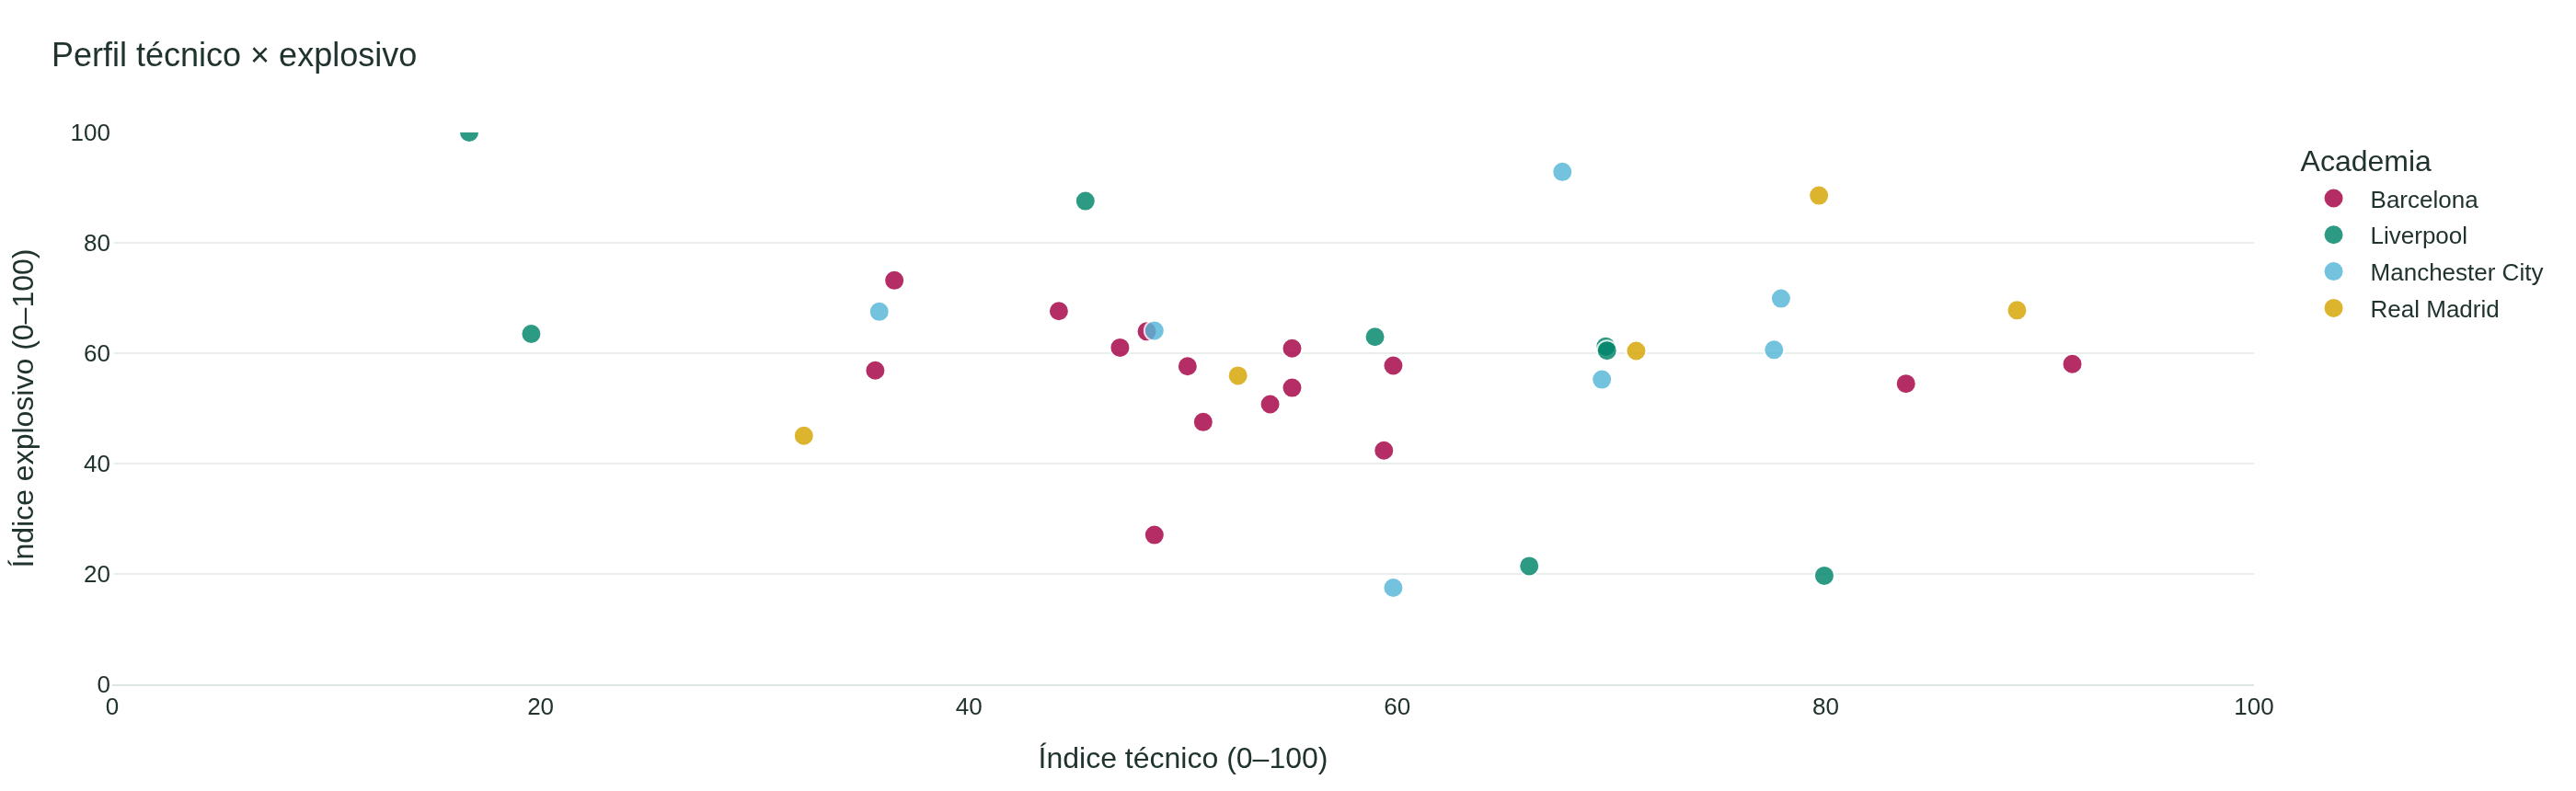

boxplots_indices.png


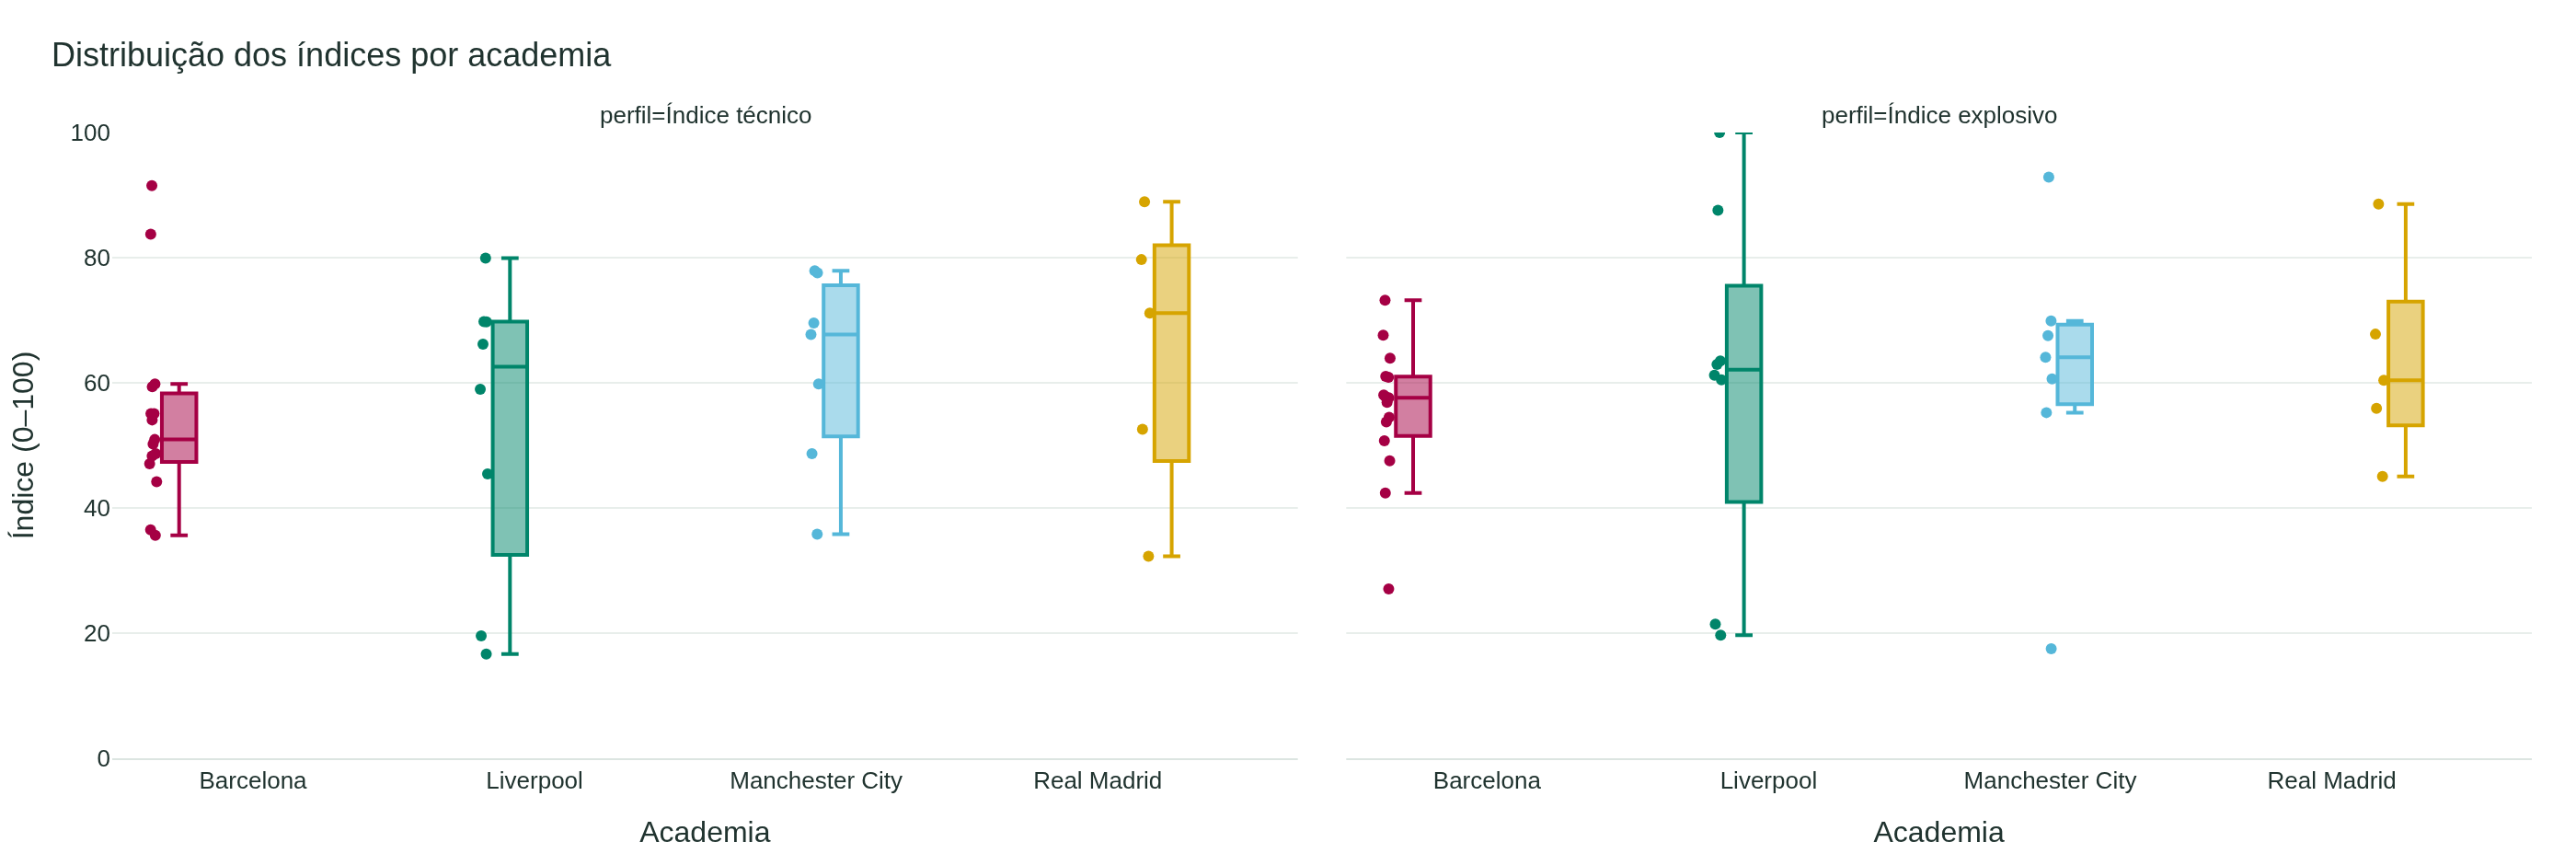

jogadores_revelados.png


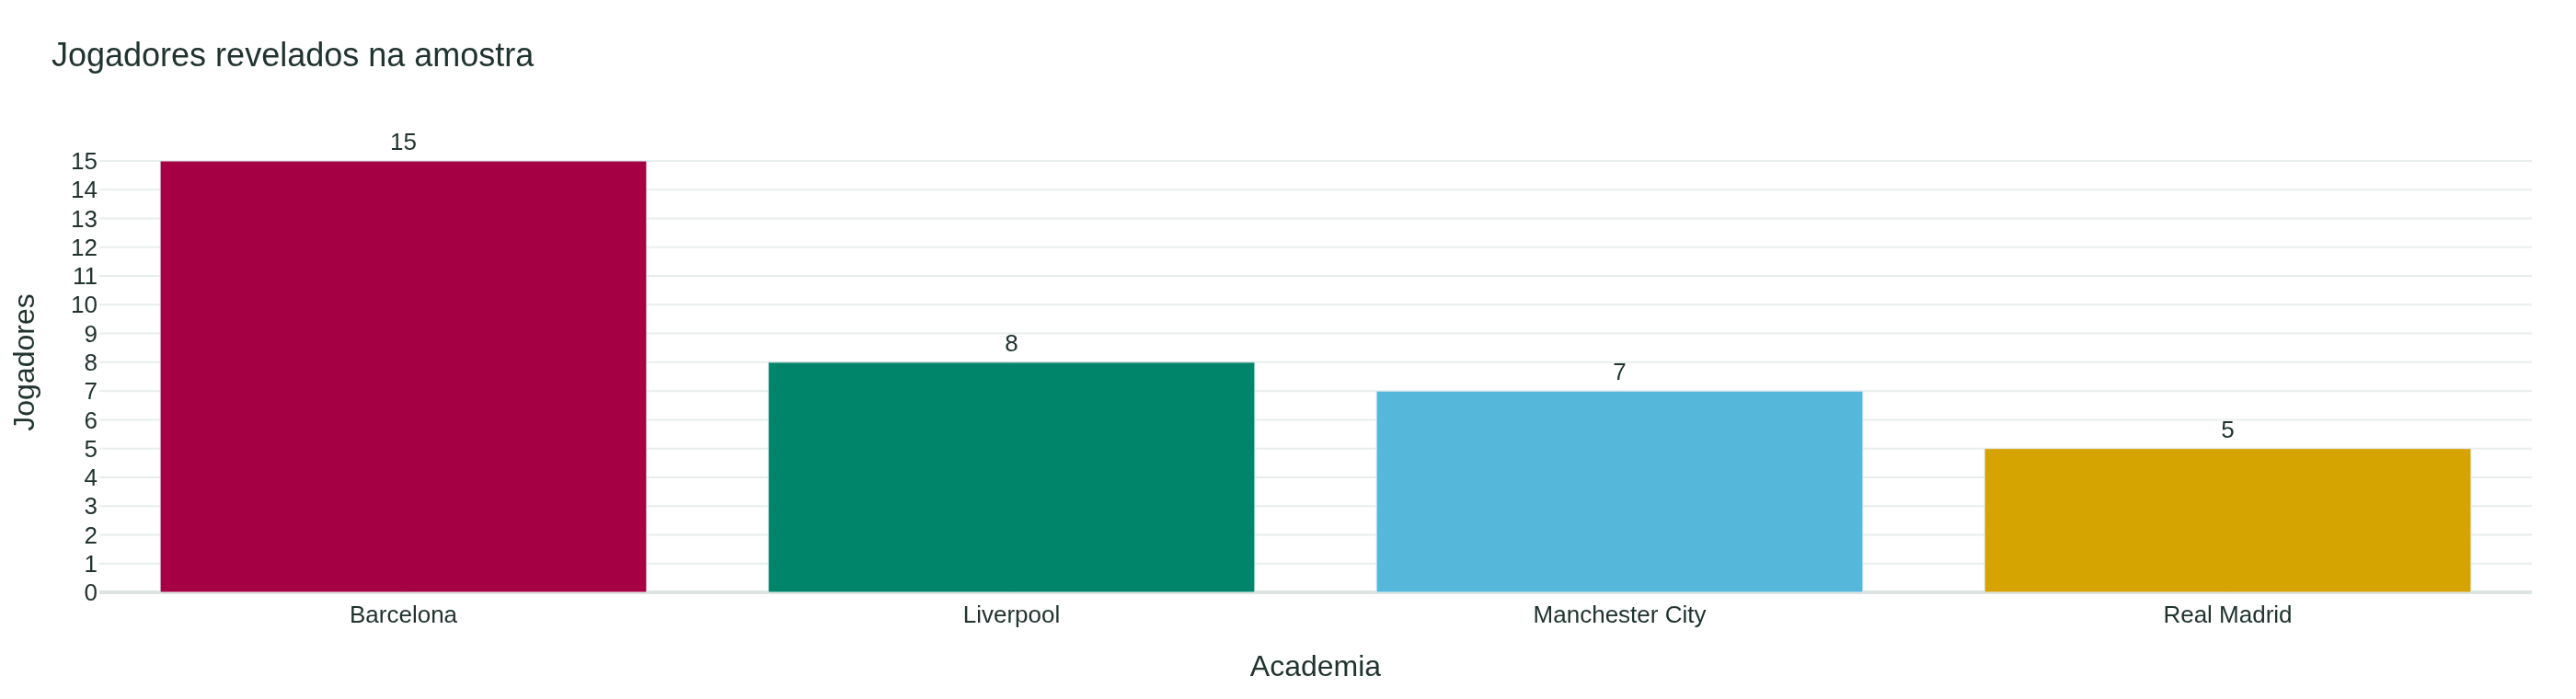

idade_estreia.png


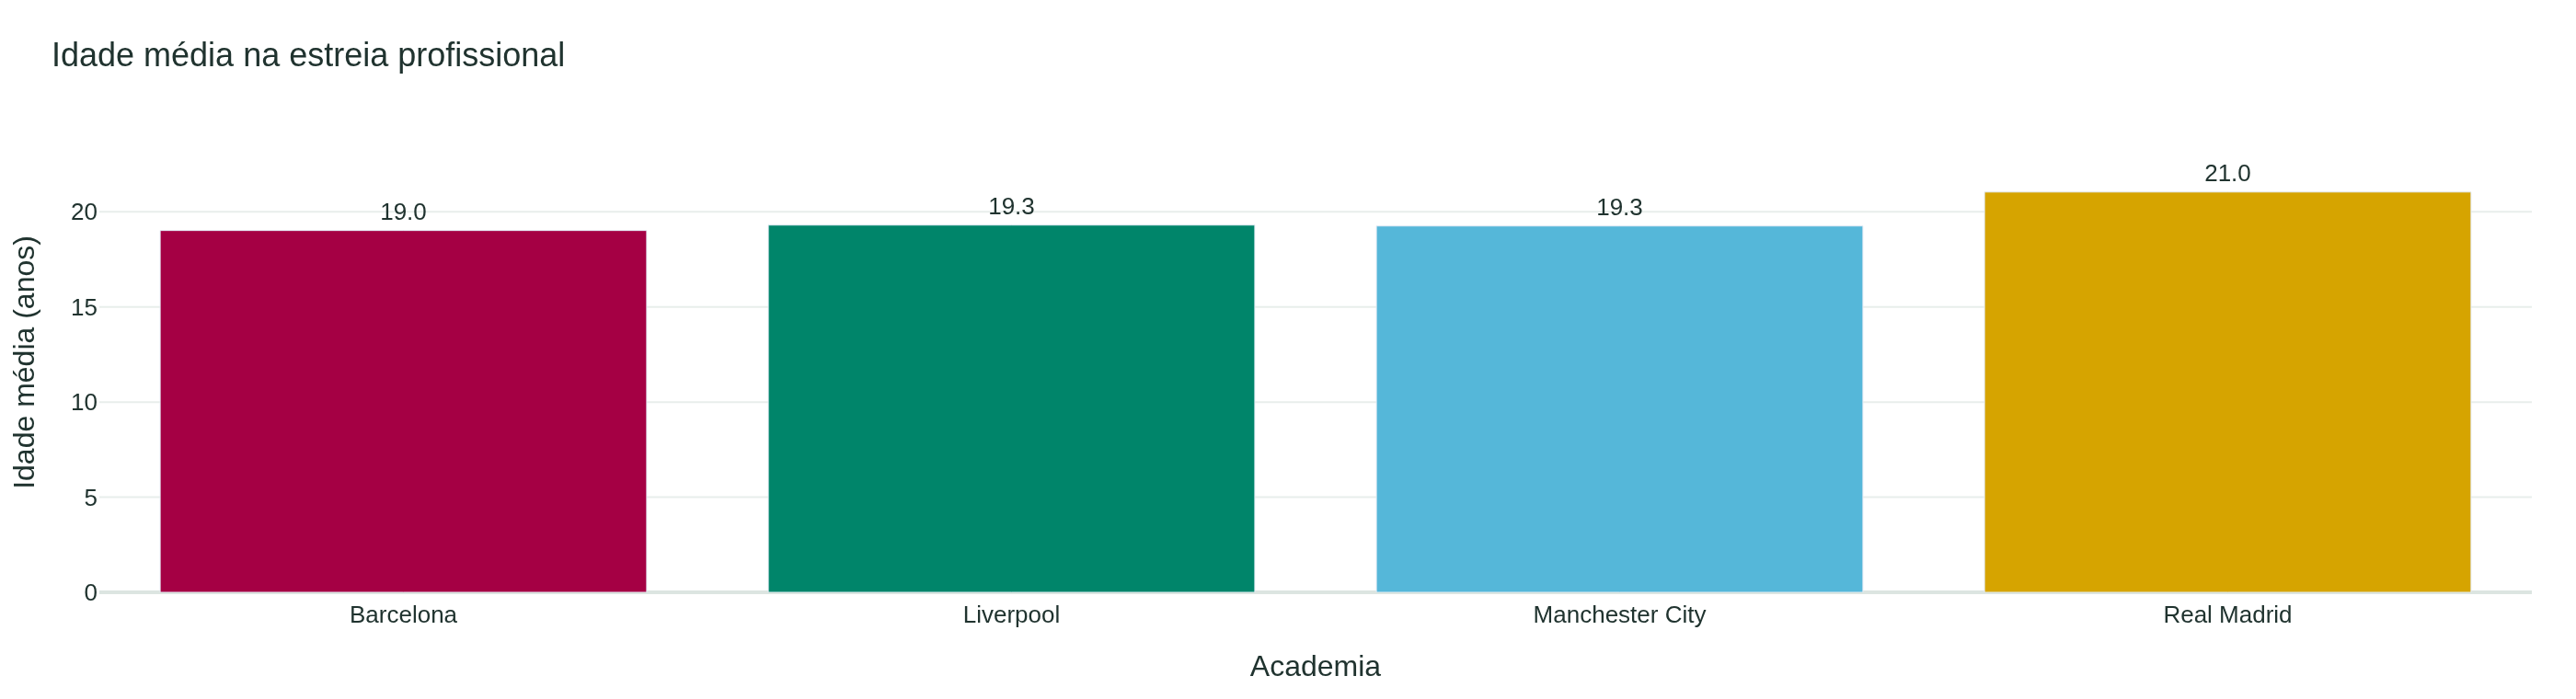

In [5]:
figuras = [
    "dispersao_tecnico_explosivo.png",
    "boxplots_indices.png",
    "jogadores_revelados.png",
    "idade_estreia.png",
]
for nome_figura in figuras:
    caminho = DIR_GRAFICOS / nome_figura
    if caminho.exists():
        print(nome_figura)
        display(Image(filename=str(caminho), width=900))
    else:
        print(f"Figura ainda não gerada: {nome_figura}. Rode python run_pipeline.py.")

## Conclusão, limitações e próximos passos

Para esta amostra, os dois testes globais não indicam diferenças estatisticamente significativas entre as academias. As comparações par a par ajustadas devem ser interpretadas da mesma forma. Isso não comprova igualdade: os grupos são pequenos e desiguais, e a potência estatística é limitada.

O índice explosivo é aproximado, pois usa indicadores substitutos de capacidade física. Os resultados descrevem os jogadores selecionados e não permitem atribuir causalidade à academia.

Próximos passos possíveis: ampliar a amostra, acrescentar fontes complementares de trajetória e atualizar periodicamente as análises e o banco SQLite.